<a href="https://colab.research.google.com/github/Mohtasim4458/Artificial-Intelligence/blob/main/AI_GRADED_LAB_03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
!pip install networkx matplotlib

IDDFS, goal = J
Depth limit 0: visited A                        ( 1 nodes) -> cutoff
Depth limit 1: visited A B C                    ( 3 nodes) -> cutoff
Depth limit 2: visited A B D E C F G            ( 7 nodes) -> cutoff
Depth limit 3: visited A B D H I E J            ( 7 nodes) -> found
Goal found at depth: 3
Path: A -> B -> E -> J
Total nodes visited by IDDFS (all iterations): 18

BFS, goal = J
Visited: A B C D E F G H I J
Path: A -> B -> E -> J
Total nodes visited by BFS: 10

=== Comparison ===
Algorithm Nodes visited  
IDDFS     18             
BFS       10             
IDDFS visited 8 more nodes than BFS (1.8x)
because it re-visits the upper levels in every iteration.


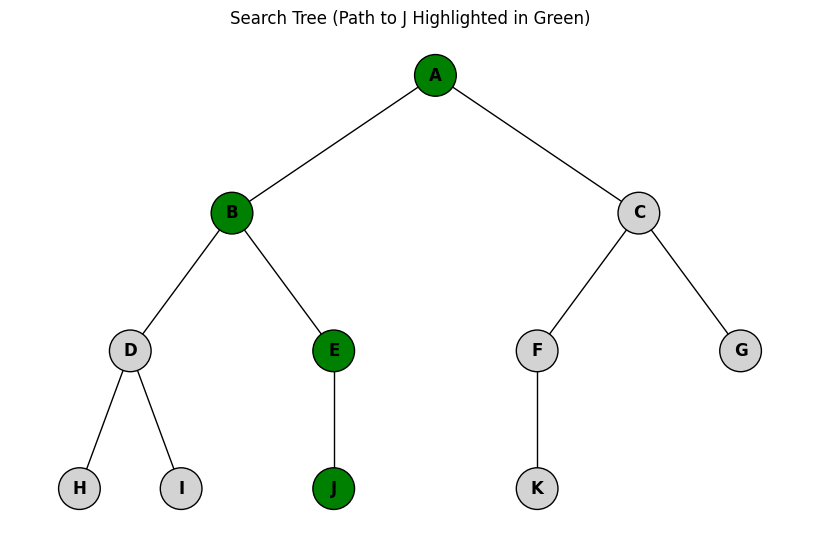

Image saved as lab04_tree.png


In [6]:
import networkx as nx
import matplotlib.pyplot as plt
from collections import deque

tree = {
    'A': ['B', 'C'],
    'B': ['D', 'E'],
    'C': ['F', 'G'],
    'D': ['H', 'I'],
    'E': ['J'],
    'F': ['K'],
    'G': [],
    'H': [],
    'I': [],
    'J': [],
    'K': []
}

# Depth-Limited Search
def dls(node, goal, limit, visited_order, path):
    visited_order.append(node)
    path.append(node)

    if node == goal:
        return 'found', path

    if limit == 0:
        path.pop()
        return 'cutoff', None

    cutoff_occurred = False

    for child in tree[node]:
        res, p = dls(child, goal, limit - 1, visited_order, path)

        if res == 'found':
            return 'found', p

        if res == 'cutoff':
            cutoff_occurred = True

    path.pop()

    return ('cutoff', None) if cutoff_occurred else ('failure', None)


# Iterative Deepening Depth-First Search
def iddfs(start, goal, max_depth=10):
    total_visited = 0

    for depth in range(max_depth + 1):
        order, path = [], []

        res, sol_path = dls(start, goal, depth, order, path)

        total_visited += len(order)

        visited = ' '.join(order)

        print(f'Depth limit {depth}: visited {visited:<24} ({len(order):>2} nodes) -> {res}')

        if res == 'found':
            return depth, sol_path, total_visited

        if res == 'failure':
            return None, None, total_visited

    return None, None, total_visited


# Breadth-First Search
def bfs(start, goal):
    queue = deque([[start]])
    order = []

    while queue:
        path = queue.popleft()
        node = path[-1]

        order.append(node)

        if node == goal:
            return path, order

        for child in tree[node]:
            queue.append(path + [child])

    return None, order


GOAL_NODE = 'J'

# IDDFS
print('IDDFS, goal =', GOAL_NODE)

depth_found, iddfs_path, iddfs_total = iddfs('A', GOAL_NODE)

print('Goal found at depth:', depth_found)
print('Path:', ' -> '.join(iddfs_path))
print('Total nodes visited by IDDFS (all iterations):', iddfs_total)

# BFS
print()
print('BFS, goal =', GOAL_NODE)

bfs_path, bfs_order = bfs('A', GOAL_NODE)

print('Visited:', ' '.join(bfs_order))
print('Path:', ' -> '.join(bfs_path))
print('Total nodes visited by BFS:', len(bfs_order))

# Comparison
print()
print('=== Comparison ===')
print(f"{'Algorithm':<10}{'Nodes visited':<15}")
print(f"{'IDDFS':<10}{iddfs_total:<15}")
print(f"{'BFS':<10}{len(bfs_order):<15}")

extra = iddfs_total - len(bfs_order)

print(f'IDDFS visited {extra} more nodes than BFS ({iddfs_total / len(bfs_order):.1f}x)')
print('because it re-visits the upper levels in every iteration.')
# Create directed graph
G = nx.DiGraph([(p, c) for p, cs in tree.items() for c in cs])

# Set tree positions
pos = {
    'A': (0, 3),
    'B': (-1, 2),
    'C': (1, 2),
    'D': (-1.5, 1),
    'E': (-0.5, 1),
    'F': (0.5, 1),
    'G': (1.5, 1),
    'H': (-1.75, 0),
    'I': (-1.25, 0),
    'J': (-0.5, 0),
    'K': (0.5, 0)
}

# Highlight solution path
solution_nodes = ['A', 'B', 'E', 'J']

colors = [
    'green' if node in solution_nodes else 'lightgrey'
    for node in G.nodes
]

# Draw tree
plt.figure(figsize=(8, 5))

nx.draw(
    G,
    pos,
    with_labels=True,
    node_color=colors,
    node_size=900,
    edgecolors='black',
    font_weight='bold',
    arrows=False
)

plt.title('Search Tree (Path to J Highlighted in Green)')

# Save image
plt.savefig('lab04_tree.png', dpi=130, bbox_inches='tight')

plt.show()

print('Image saved as lab04_tree.png')

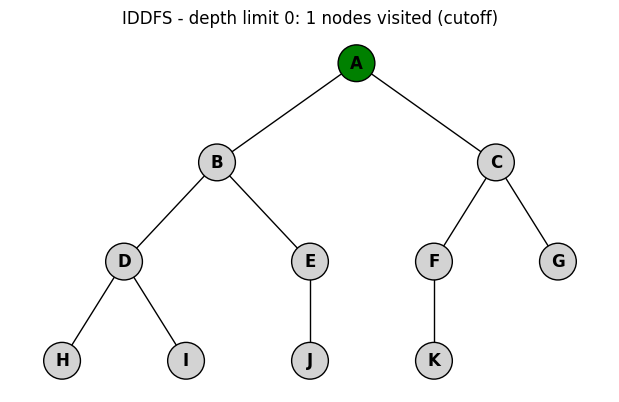

Saved iddfs_depth_0.png


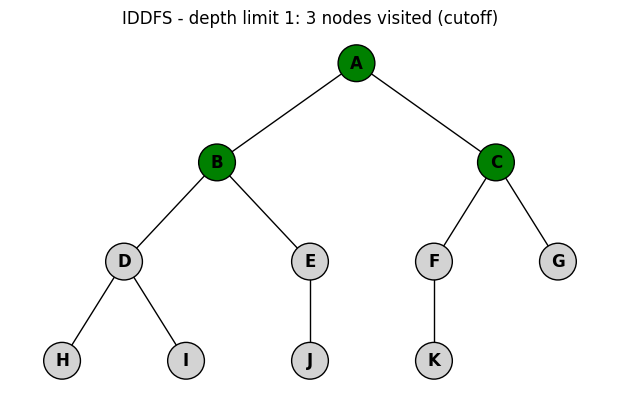

Saved iddfs_depth_1.png


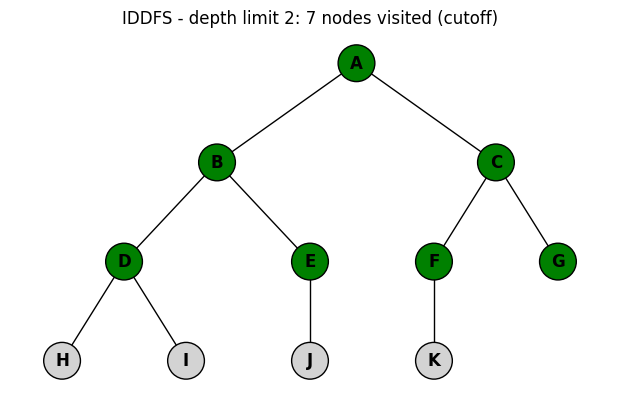

Saved iddfs_depth_2.png


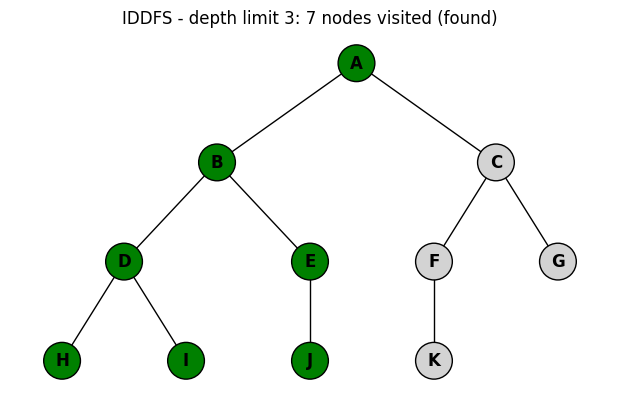

Saved iddfs_depth_3.png


In [7]:
import networkx as nx
import matplotlib.pyplot as plt

tree = {
    'A': ['B', 'C'],
    'B': ['D', 'E'],
    'C': ['F', 'G'],
    'D': ['H', 'I'],
    'E': ['J'],
    'F': ['K'],
    'G': [],
    'H': [],
    'I': [],
    'J': [],
    'K': []
}

# Depth-Limited Search
def dls(node, goal, limit, visited_order, path):
    visited_order.append(node)
    path.append(node)

    if node == goal:
        return 'found', path

    if limit == 0:
        path.pop()
        return 'cutoff', None

    cutoff_occurred = False

    for child in tree[node]:
        res, p = dls(child, goal, limit - 1, visited_order, path)

        if res == 'found':
            return 'found', p

        if res == 'cutoff':
            cutoff_occurred = True

    path.pop()

    return ('cutoff', None) if cutoff_occurred else ('failure', None)


# Create directed graph
G = nx.DiGraph([(p, c) for p, cs in tree.items() for c in cs])

# Layered layout
pos, next_x = {}, [0]

def layout(n, d=0):
    kids = tree[n]

    if not kids:
        pos[n] = (next_x[0], -d)
        next_x[0] += 1
    else:
        for k in kids:
            layout(k, d + 1)

        pos[n] = (
            sum(pos[k][0] for k in kids) / len(kids),
            -d
        )

layout('A')

GOAL_NODE = 'J'

# Calculate depth of the found path
depth_found = 3

# Draw graph for each depth limit
for limit in range(depth_found + 1):

    order, path = [], []

    res, _ = dls('A', GOAL_NODE, limit, order, path)

    colors = [
        'green' if n in order else 'lightgrey'
        for n in G.nodes
    ]

    plt.figure(figsize=(6, 3.6))

    nx.draw(
        G,
        pos,
        with_labels=True,
        node_color=colors,
        node_size=700,
        edgecolors='black',
        font_weight='bold',
        arrows=False
    )

    plt.title(
        f'IDDFS - depth limit {limit}: {len(order)} nodes visited ({res})'
    )

    plt.savefig(
        f'iddfs_depth_{limit}.png',
        dpi=130,
        bbox_inches='tight'
    )

    plt.show()

    print(f'Saved iddfs_depth_{limit}.png')

In [8]:
GOAL = (1, 2, 3, 4, 5, 6, 7, 8, 0)

START = (1, 2, 3, 4, 0, 6, 7, 5, 8)


# Generate neighboring states
def neighbors(state):
    i = state.index(0)

    r, c = divmod(i, 3)

    result = []

    for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):

        nr, nc = r + dr, c + dc

        if 0 <= nr < 3 and 0 <= nc < 3:

            j = nr * 3 + nc

            s = list(state)

            s[i], s[j] = s[j], s[i]

            result.append(tuple(s))

    return result


# Depth-Limited Search for Puzzle
def dls_puzzle(state, limit, path, counter):

    if state == GOAL:
        return path

    if limit == 0:
        return 'cutoff'

    counter[0] += 1

    cutoff_occurred = False

    for nxt in neighbors(state):

        if nxt in path:
            continue

        res = dls_puzzle(
            nxt,
            limit - 1,
            path + [nxt],
            counter
        )

        if res == 'cutoff':
            cutoff_occurred = True

        elif res is not None:
            return res

    return 'cutoff' if cutoff_occurred else None


# Iterative Deepening DFS
def iddfs_puzzle(start, max_depth=30):

    total_expanded = 0

    for depth in range(max_depth + 1):

        counter = [0]

        res = dls_puzzle(start, depth, [start], counter)

        total_expanded += counter[0]

        if res not in ('cutoff', None):
            return depth, res, total_expanded

    return None, None, total_expanded


# Run IDDFS
depth, solution, expanded = iddfs_puzzle(START)

print('Start state:', START)
print('Goal found at depth:', depth)
print('Number of nodes expanded:', expanded)

print('Solution path:')

for s in solution:

    print(s[0:3])
    print(s[3:6])
    print(s[6:9])
    print()

Start state: (1, 2, 3, 4, 0, 6, 7, 5, 8)
Goal found at depth: 2
Number of nodes expanded: 4
Solution path:
(1, 2, 3)
(4, 0, 6)
(7, 5, 8)

(1, 2, 3)
(4, 5, 6)
(7, 0, 8)

(1, 2, 3)
(4, 5, 6)
(7, 8, 0)



In [9]:
# 0 = open cell, 1 = wall

maze = [
    [0, 0, 0, 1, 0, 0, 0],
    [1, 1, 0, 1, 0, 1, 0],
    [0, 0, 0, 0, 0, 1, 0],
    [0, 1, 1, 1, 0, 0, 0],
    [0, 0, 0, 1, 0, 1, 0],
    [1, 1, 0, 0, 0, 1, 0],
    [0, 0, 0, 1, 0, 0, 0]
]

MAZE_START = (0, 0)

MAZE_GOAL = (6, 6)

ROWS, COLS = len(maze), len(maze[0])


# Depth-Limited Search on Maze
def dls_maze(pos, limit, path):

    if pos == MAZE_GOAL:
        return path

    if limit == 0:
        return 'cutoff'

    cutoff_occurred = False

    r, c = pos

    for dr, dc in ((0, 1), (1, 0), (0, -1), (-1, 0)):

        nr, nc = r + dr, c + dc

        if (
            0 <= nr < ROWS
            and 0 <= nc < COLS
            and maze[nr][nc] == 0
            and (nr, nc) not in path
        ):

            res = dls_maze(
                (nr, nc),
                limit - 1,
                path + [(nr, nc)]
            )

            if res == 'cutoff':
                cutoff_occurred = True

            elif res is not None:
                return res

    return 'cutoff' if cutoff_occurred else None


# Test different depth limits
for limit in (5, 10, 15):

    res = dls_maze(
        MAZE_START,
        limit,
        [MAZE_START]
    )

    if res == 'cutoff':

        print(f'Limit {limit:>2}: CUTOFF')

    elif res is None:

        print(f'Limit {limit:>2}: FAILURE (no path)')

    else:

        print(f'Limit {limit:>2}: FOUND, path length = {len(res) - 1} steps')

        print('        ', res)

Limit  5: CUTOFF
Limit 10: CUTOFF
Limit 15: FOUND, path length = 12 steps
         [(0, 0), (0, 1), (0, 2), (1, 2), (2, 2), (2, 3), (2, 4), (3, 4), (3, 5), (3, 6), (4, 6), (5, 6), (6, 6)]
